Loading data from /kyb/agpd/wwang/sst-pomdp/outputs...
Data Loaded. Valid Subjects: 5918
Generating UMAP Grid (3x3)...


/kyb/agpd/wwang/tst/testenv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


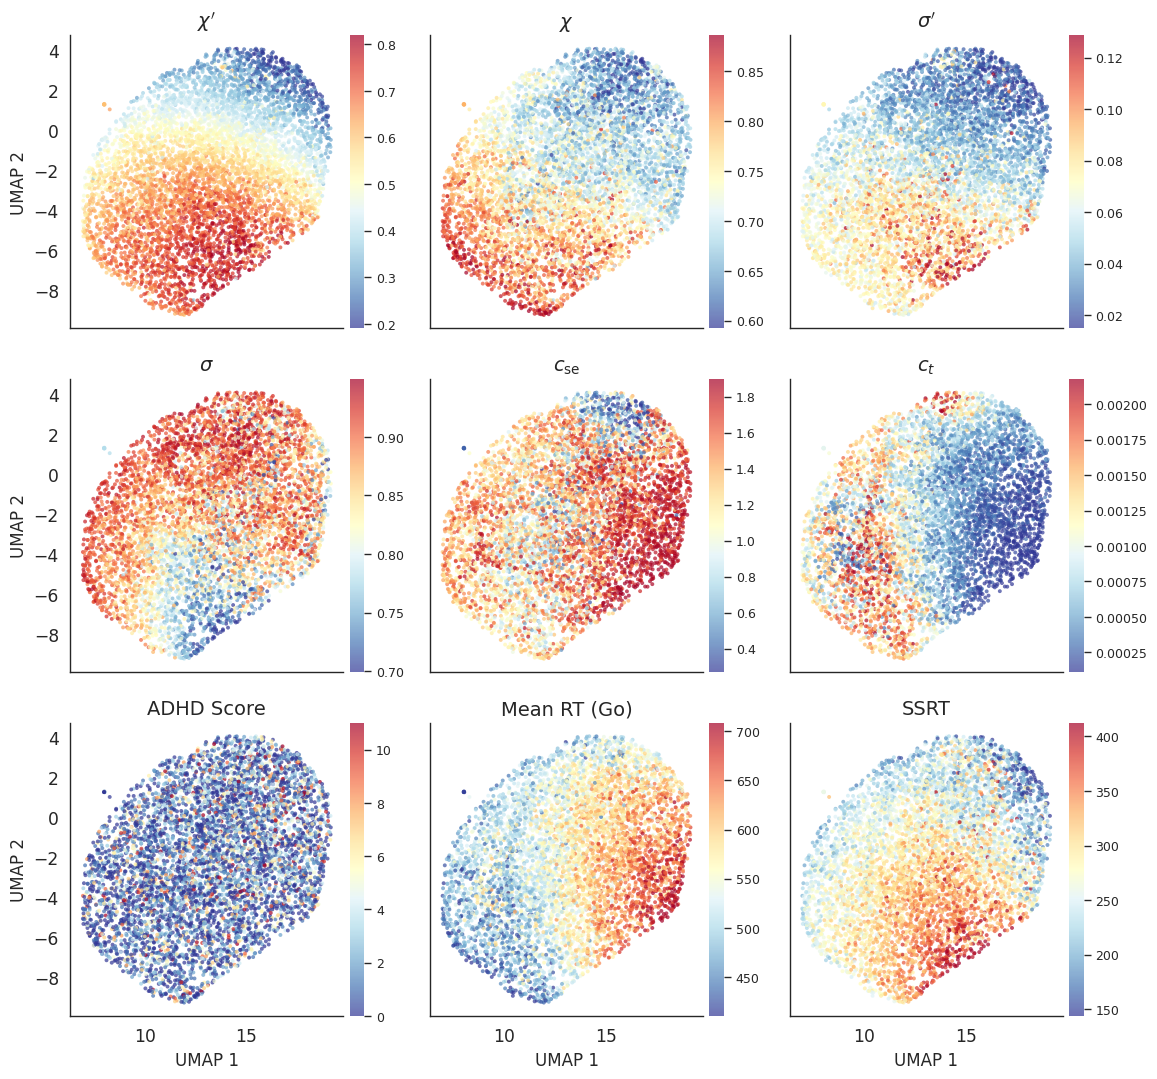

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.preprocessing import StandardScaler
from pathlib import Path

# ==========================================
# 0. Path Definitions & Style
# ==========================================
BASE_DIR = Path('/kyb/agpd/wwang/data/')
OUT_DIR = Path('/kyb/agpd/wwang/sst-pomdp/outputs/')

# Journal Style Settings
sns.set_context("paper", font_scale=1.4)
sns.set_style("white") 

# Display Names for Titles
DISPLAY_NAMES = {
    # POMDP Parameters
    'q_d_n': r"$\chi'$",
    'q_d': r"$\chi$",
    'q_s_n': r"$\sigma'$",
    'q_s': r"$\sigma$",
    'cost_stop_error': r"$c_{\mathrm{se}}$",
    'cost_time': r"$c_t$",
    # Clinical / Behavioral
    'adhd': 'ADHD Score',
    'mrt_gs': 'Mean RT (Go)',
    'ssrt': 'SSRT',
}

# ==========================================
# 1. Data Loading & Filtering
# ==========================================
def load_and_filter_data():
    print(f"Loading data from {OUT_DIR}...")
    
    # Load Main Files
    df_emb = pd.read_csv(OUT_DIR / 'embeddings.csv')
    df_stats = pd.read_csv(OUT_DIR / 'stats_beh_full.csv')
    df_post = pd.read_csv(OUT_DIR / 'posterior_summary.csv')

    # Convert years to string for merging
    for df in [df_emb, df_stats, df_post]:
        if 'year' in df.columns: df['year'] = df['year'].astype(str)
        if 'subject_year' in df.columns: df['subject_year'] = df['subject_year'].astype(str)

    # Pivot Posterior
    df_post_pivot = df_post.pivot_table(index=['subject_id', 'subject_year'], 
                                        columns='param', 
                                        values='mean').reset_index()
    df_post_pivot.rename(columns={'subject_year': 'year'}, inplace=True)

    # Merge All
    df = pd.merge(df_emb, df_stats, on=['subject_id', 'year', 'filename'])
    df_final = pd.merge(df, df_post_pivot, on=['subject_id', 'year'])
    
    print(f"Data Loaded. Valid Subjects: {len(df_final)}")
    return df_final

# ==========================================
# 2. Visualization: UMAP Grid (3x3)
# ==========================================
def plot_umap_grid(df):
    print("Generating UMAP Grid (3x3)...")

    # Prepare Embeddings
    embedding_cols = [f'emb_{i}' for i in range(64)]
    X = StandardScaler().fit_transform(df[embedding_cols].values)

    # Run UMAP
    reducer = umap.UMAP(n_neighbors=30, min_dist=0.5, random_state=42)
    u_emb = reducer.fit_transform(X)
    
    df['umap_1'] = u_emb[:, 0]
    df['umap_2'] = u_emb[:, 1]
    
    # Targets: 6 Parameters + 3 Clinical
    targets = [
        'q_d_n', 'q_d', 'q_s_n', 
        'q_s', 'cost_stop_error', 'cost_time',
        'adhd', 'mrt_gs', 'ssrt'
    ]
    
    # Create 3x3 Grid
    fig, axes = plt.subplots(3, 3, figsize=(12, 11), sharex=True, sharey=True)
    axes = axes.flatten()

    for i, var in enumerate(targets):
        if var in df.columns:
            # Color Map Selection
            cmap_choice = 'RdYlBu_r'
            
            # Scatter
            vmin, vmax = df[var].quantile([0.01, 0.99])
            sc = axes[i].scatter(df['umap_1'], df['umap_2'], 
                                 c=df[var], cmap=cmap_choice, 
                                 alpha=0.7, s=8, linewidth=0, 
                                 vmin=vmin, vmax=vmax)
            
            # Title & Spines
            axes[i].set_title(DISPLAY_NAMES.get(var, var), fontsize=14)
            axes[i].spines['top'].set_visible(False)
            axes[i].spines['right'].set_visible(False)
            
            # Axis Labels (Only on edges)
            if i >= 6: # Bottom row
                axes[i].set_xlabel("UMAP 1", fontsize=12)
            if i % 3 == 0: # Left column
                axes[i].set_ylabel("UMAP 2", fontsize=12)
            
            # Colorbar
            cbar = plt.colorbar(sc, ax=axes[i], pad=0.02)
            cbar.ax.tick_params(labelsize=9)
            cbar.outline.set_visible(False)
        else:
            axes[i].axis('off')
            
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'embed_umap.png', dpi=300, bbox_inches='tight')
    plt.show()

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    df = load_and_filter_data()
    plot_umap_grid(df)

In [11]:
import plotly.graph_objects as go
from plotly.offline import plot

# ... (Keep your existing imports and setup) ...

def plot_umap_3d_interactive(df, filename="interactive_umap_3d.html"):
    print("Generating Interactive 3D UMAP (Calculating 3 components, please wait)...")
    
    # 1. Re-run UMAP with n_components=3
    embedding_cols = [f'emb_{i}' for i in range(64)]
    X = StandardScaler().fit_transform(df[embedding_cols].values)
    
    # Critical: n_components=3
    reducer_3d = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.5, random_state=42)
    u_3d = reducer_3d.fit_transform(X)
    
    df['umap_1'] = u_3d[:, 0]
    df['umap_2'] = u_3d[:, 1]
    df['umap_3'] = u_3d[:, 2]

    # 2. Define Targets
    targets = [
        'adhd', 'mrt_gs', 'ssrt', 
        'q_d', 'q_d_n', 'q_s', 'q_s_n', 
        'cost_stop_error', 'cost_time'
    ]

    # 3. Create Figure
    fig = go.Figure()

    # Add default trace
    default_var = targets[0]
    fig.add_trace(go.Scatter3d(
        x=df['umap_1'], y=df['umap_2'], z=df['umap_3'],
        mode='markers',
        marker=dict(
            size=1.5,
            color=df[default_var],
            colorscale='RdYlBu_r',
            opacity=0.8,
            colorbar=dict(title=DISPLAY_NAMES.get(default_var, default_var))
        ),
        text=[f"ID: {s}<br>Val: {v:.2f}" for s, v in zip(df['subject_id'], df[default_var])],
        hoverinfo='text'
    ))

    # 4. Create Dropdown Buttons
    buttons = []
    for var in targets:
        if var not in df.columns: continue
        
        label = DISPLAY_NAMES.get(var, var)
        cmap = 'RdYlBu_r' if var in ['adhd', 'mrt_gs', 'ssrt'] else 'mako_r'
        
        buttons.append(dict(
            label=label,
            method="restyle",
            args=[{
                'marker.color': [df[var]],
                'marker.colorscale': cmap,
                'marker.colorbar.title': label,
                'text': [[f"ID: {s}<br>{label}: {v:.2f}" for s, v in zip(df['subject_id'], df[var])]]
            }]
        ))

    # 5. Update Layout
    fig.update_layout(
        title="3D UMAP Manifold",
        scene=dict(xaxis_title='UMAP 1', yaxis_title='UMAP 2', zaxis_title='UMAP 3'),
        width=1000, height=800,
        updatemenus=[dict(
            active=0, buttons=buttons,
            x=0.1, y=0.9, xanchor='left', yanchor='top',
            bgcolor='white'
        )]
    )

    # 6. Save
    save_path = OUT_DIR / filename
    plot(fig, filename=str(save_path), auto_open=False)
    print(f"Saved interactive UMAP plot to: {save_path}")

# --- Add this line to your 'if __name__ == "__main__":' block ---
plot_umap_3d_interactive(df)

Generating Interactive 3D UMAP (Calculating 3 components, please wait)...


/kyb/agpd/wwang/tst/testenv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



Saved interactive UMAP plot to: /kyb/agpd/wwang/sst-pomdp/outputs/interactive_umap_3d.html
